<a href="https://colab.research.google.com/github/paskalunivers/clustering/blob/main/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# BLOK 1 — INPUT
# Import Library & Load Dataset

!pip install scikit-learn pandas numpy matplotlib seaborn scipy --quiet

print("Semua library berhasil diinstall.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import SpectralClustering, KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"

# ── Load Dataset ───

df_raw = pd.read_csv("salesdaily.csv")

print("=" * 55)
print("  DATASET BERHASIL DIMUAT")
print("=" * 55)
print(f"  Jumlah baris  : {df_raw.shape[0]:,}")
print(f"  Jumlah kolom  : {df_raw.shape[1]}")
print(f"  Periode data  : {df_raw['Year'].min()} – {df_raw['Year'].max()}")
print("=" * 55)
print("\n[Sampel 5 Baris Pertama]")
display(df_raw.head())
print("\n[Tipe Data per Kolom]")
print(df_raw.dtypes)

Semua library berhasil diinstall.
  DATASET BERHASIL DIMUAT
  Jumlah baris  : 2,106
  Jumlah kolom  : 13
  Periode data  : 2014 – 2019

[Sampel 5 Baris Pertama]


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday



[Tipe Data per Kolom]
datum            object
M01AB           float64
M01AE           float64
N02BA           float64
N02BE           float64
N05B            float64
N05C            float64
R03             float64
R06             float64
Year              int64
Month             int64
Hour              int64
Weekday Name     object
dtype: object


In [ ]:

# BLOK 2 — PROSES: DATA CLEANING


df = df_raw.copy()

# ── 2.1 Cek Missing Value
missing = df.isnull().sum()
print("=" * 55)
print("  CEK MISSING VALUE")
print("=" * 55)
print(missing.to_string())
print(f"\nTotal nilai kosong   : {missing.sum()}")

# ── 2.2 Cek Duplikat
duplikat = df.duplicated().sum()
print(f"Total baris duplikat : {duplikat}")

# ── 2.3 Konversi Kolom Tanggal
df["datum"] = pd.to_datetime(df["datum"], format="mixed")
df = df.sort_values("datum").reset_index(drop=True)

print(f"\nRentang tanggal : {df['datum'].min().date()} s/d {df['datum'].max().date()}")

# ── 2.4 Definisi Kolom Kategori Obat ATC
ATC_COLS = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]

print("\n[Data Setelah Cleaning — 10 Baris Pertama]")
display(df[["datum"] + ATC_COLS].head(10))

print("\n[Statistik Deskriptif Fitur Obat]")
display(df[ATC_COLS].describe().round(3))

print("\nData Cleaning selesai.")

  CEK MISSING VALUE
datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0

Total nilai kosong   : 0
Total baris duplikat : 0

Rentang tanggal : 2014-01-02 s/d 2019-10-08

[Data Setelah Cleaning — 10 Baris Pertama]


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-02,0.00,3.67,3.4,32.40,7.0,0.0,0.0,2.0
1,2014-01-03,8.00,4.00,4.4,50.60,16.0,0.0,20.0,4.0
2,2014-01-04,2.00,1.00,6.5,61.85,10.0,0.0,9.0,1.0
3,2014-01-05,4.00,3.00,7.0,41.10,8.0,0.0,3.0,0.0
4,2014-01-06,5.00,1.00,4.5,21.70,16.0,2.0,6.0,2.0
5,2014-01-07,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0
6,2014-01-08,5.33,3.00,10.5,26.40,19.0,1.0,10.0,0.0
7,2014-01-09,7.00,1.68,8.0,25.00,16.0,0.0,3.0,2.0
8,2014-01-10,5.00,2.00,2.0,53.30,15.0,2.0,0.0,2.0
9,2014-01-11,5.00,4.34,10.4,52.30,14.0,0.0,1.0,0.2



[Statistik Deskriptif Fitur Obat]


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,2106.000,2106.000,2106.000,2106.000,2106.000,2106.000,2106.000,2106.000
mean,5.034,3.896,3.880,29.917,8.854,0.594,5.512,2.900
std,2.738,2.133,2.384,15.591,5.606,1.093,6.429,2.416
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,3.000,2.340,2.000,19.000,5.000,0.000,1.000,1.000
50%,4.990,3.670,3.500,26.900,8.000,0.000,4.000,2.000
75%,6.670,5.138,5.200,38.300,12.000,1.000,8.000,4.000
max,17.340,14.463,16.000,161.000,54.833,9.000,45.000,15.000



Data Cleaning selesai.


In [ ]:
#   BLOK 3 — PROSES: MIN-MAX NORMALISASI

# Rumus: x' = (x - x_min) / (x_max - x_min)

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df[ATC_COLS])
df_scaled = pd.DataFrame(X_scaled, columns=ATC_COLS, index=df.index)

print("=" * 60)
print("  HASIL MIN-MAX NORMALISASI")
print("=" * 60)
print(f"\n{'Fitur':<10} {'Min Asli':>12} {'Max Asli':>12} {'Min Normal':>12} {'Max Normal':>12}")
print("-" * 60)
for col in ATC_COLS:
    print(f"{col:<10} {df[col].min():>12.3f} {df[col].max():>12.3f} "
          f"{df_scaled[col].min():>12.3f} {df_scaled[col].max():>12.3f}")

print("\n[Sampel Data Setelah Normalisasi — 10 Baris Pertama]")
display(df_scaled.head(10))

print("\nNormalisasi selesai.")

  HASIL MIN-MAX NORMALISASI

Fitur          Min Asli     Max Asli   Min Normal   Max Normal
------------------------------------------------------------
M01AB             0.000       17.340        0.000        1.000
M01AE             0.000       14.463        0.000        1.000
N02BA             0.000       16.000        0.000        1.000
N02BE             0.000      161.000        0.000        1.000
N05B              0.000       54.833        0.000        1.000
N05C              0.000        9.000        0.000        1.000
R03               0.000       45.000        0.000        1.000
R06               0.000       15.000        0.000        1.000

[Sampel Data Setelah Normalisasi — 10 Baris Pertama]


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,0.000000,0.253751,0.21250,0.201242,0.127660,0.000000,0.000000,0.133333
1,0.461361,0.276568,0.27500,0.314286,0.291793,0.000000,0.444444,0.266667
2,0.115340,0.069142,0.40625,0.384161,0.182371,0.000000,0.200000,0.066667
3,0.230681,0.207426,0.43750,0.255280,0.145897,0.000000,0.066667,0.000000
4,0.288351,0.069142,0.28125,0.134783,0.291793,0.222222,0.133333,0.133333
5,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.307382,0.207426,0.65625,0.163975,0.346505,0.111111,0.222222,0.000000
7,0.403691,0.116158,0.50000,0.155280,0.291793,0.000000,0.066667,0.133333
8,0.288351,0.138284,0.12500,0.331056,0.273556,0.222222,0.000000,0.133333
9,0.288351,0.300076,0.65000,0.324845,0.255319,0.000000,0.022222,0.013333



Normalisasi selesai.


In [ ]:
#   BLOK 4 — PROSES: FEATURE ENGINEERING

# 4.1 Hitung Statistik Agregat per Kategori Obat
feature_dict = {}
for col in ATC_COLS:
    feature_dict[col] = {
        "Total_Sales"    : df[col].sum(),
        "Mean_Daily"     : df[col].mean(),
        "Std_Daily"      : df[col].std(),
        "Max_Daily"      : df[col].max(),
        "Min_Daily"      : df[col].min(),
        "Freq_Transaksi" : (df[col] > 0).sum() / len(df),
        "Coef_Variation" : df[col].std() / (df[col].mean() + 1e-9)
    }

df_features = pd.DataFrame(feature_dict).T.reset_index()
df_features.columns = ["Kategori_ATC", "Total_Sales", "Mean_Daily",
                        "Std_Daily", "Max_Daily", "Min_Daily",
                        "Freq_Transaksi", "Coef_Variation"]

# ── 4.2 Simulasi Indeks Margin
margin_map = {
    "M01AB": "Sedang",
    "M01AE": "Sedang",
    "N02BA": "Rendah",
    "N02BE": "Tinggi",
    "N05B" : "Tinggi",
    "N05C" : "Tinggi",
    "R03"  : "Sedang",
    "R06"  : "Rendah"
}
df_features["Indeks_Margin"] = df_features["Kategori_ATC"].map(margin_map)

# ── 4.3 Normalisasi Fitur untuk Clustering
CLUSTER_FEATURES = ["Total_Sales", "Mean_Daily", "Std_Daily",
                    "Freq_Transaksi", "Coef_Variation"]

scaler_feat = MinMaxScaler()
X_cluster = scaler_feat.fit_transform(df_features[CLUSTER_FEATURES])

print("=" * 60)
print("  TABEL PROFIL FITUR PER KATEGORI OBAT")
print("=" * 60)
display(df_features[["Kategori_ATC", "Total_Sales", "Mean_Daily",
                      "Freq_Transaksi", "Coef_Variation", "Indeks_Margin"]].round(4))

print("(8 kategori obat × 5 fitur agregat)")
print("\nFeature Engineering selesai.")

  TABEL PROFIL FITUR PER KATEGORI OBAT


,Kategori_ATC,Total_Sales,Mean_Daily,Freq_Transaksi,Coef_Variation,Indeks_Margin
0,M01AB,10600.9371,5.0337,0.9810,0.5439,Sedang
1,M01AE,8204.6186,3.8958,0.9829,0.5476,Sedang
2,N02BA,8172.2090,3.8804,0.9630,0.6144,Rendah
3,N02BE,63005.4027,29.9171,0.9877,0.5211,Tinggi
4,N05B,18645.7375,8.8536,0.9796,0.6331,Tinggi
5,N05C,1249.9583,0.5935,0.3210,1.8415,Tinggi
6,R03,11608.8229,5.5123,0.7702,1.1663,Sedang
7,R06,6107.8175,2.9002,0.8784,0.8330,Rendah


(8 kategori obat × 5 fitur agregat)

Feature Engineering selesai.


  MATRIKS SPECTRAL CLUSTERING

[Similarity Matrix W — (8, 8)]
[[1.     0.9976 0.9964 0.3285 0.9619 0.367  0.8238 0.9595]
 [0.9976 1.     0.9981 0.2957 0.9424 0.3722 0.8125 0.9637]
 [0.9964 0.9981 1.     0.2992 0.9476 0.4017 0.8427 0.9774]
 [0.3285 0.2957 0.2992 1.     0.4692 0.0821 0.3448 0.2717]
 [0.9619 0.9424 0.9476 0.4692 1.     0.3554 0.8646 0.9154]
 [0.367  0.3722 0.4017 0.0821 0.3554 1.     0.6353 0.5212]
 [0.8238 0.8125 0.8427 0.3448 0.8646 0.6353 1.     0.9128]
 [0.9595 0.9637 0.9774 0.2717 0.9154 0.5212 0.9128 1.    ]]

[Laplacian Matrix L — (8, 8)]
[[ 5.4347 -0.9976 -0.9964 -0.3285 -0.9619 -0.367  -0.8238 -0.9595]
 [-0.9976  5.3822 -0.9981 -0.2957 -0.9424 -0.3722 -0.8125 -0.9637]
 [-0.9964 -0.9981  5.4631 -0.2992 -0.9476 -0.4017 -0.8427 -0.9774]
 [-0.3285 -0.2957 -0.2992  2.0911 -0.4692 -0.0821 -0.3448 -0.2717]
 [-0.9619 -0.9424 -0.9476 -0.4692  5.4564 -0.3554 -0.8646 -0.9154]
 [-0.367  -0.3722 -0.4017 -0.0821 -0.3554  2.7349 -0.6353 -0.5212]
 [-0.8238 -0.8125 -0.8427 -0.344

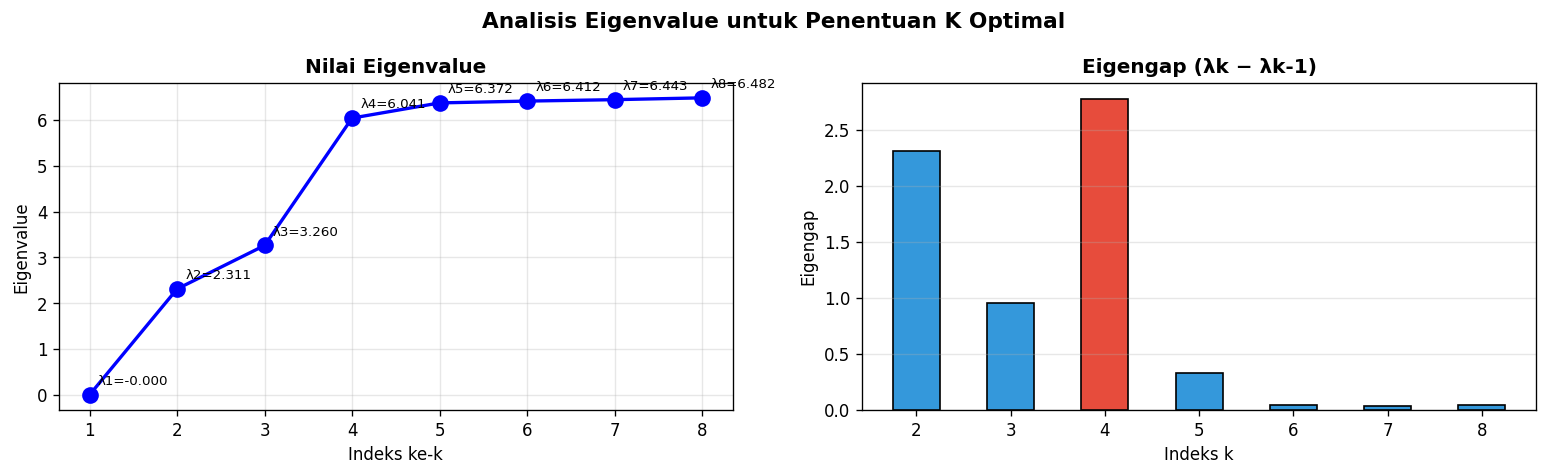

plot_eigenvalue.png disimpan

[Evaluasi Silhouette & DBI untuk Setiap Nilai K]
    K |   Silhouette  |       DBI 
  -----------------------------------
    2 |        0.5460 |     0.2681
    3 |        0.4528 |     0.5454
    4 |       -0.0388 |     0.6667
    5 |       -0.1936 |     0.7402
    6 |       -0.1749 |     0.9790
    7 |       -0.0482 |     0.5081

  K Optimal = 2  (Silhouette tertinggi)

Blok 5 selesai.


In [ ]:
#   BLOK 5 — PROSES: PENENTUAN K OPTIMAL
#   Eigengap Heuristic + Silhouette per K


sigma = 1.0
gamma = 1.0 / (2 * sigma**2)

#  5.1 Similarity Matrix W (Gaussian Kernel / Persamaan 5)
W = rbf_kernel(X_cluster, gamma=gamma)

#  5.2 Degree Matrix D
D = np.diag(W.sum(axis=1))

#  5.3 Laplacian L = D - W (Persamaan 1)
L = D - W

print("=" * 55)
print("  MATRIKS SPECTRAL CLUSTERING")
print("=" * 55)
print(f"\n[Similarity Matrix W — {W.shape}]")
print(np.round(W, 4))
print(f"\n[Laplacian Matrix L — {L.shape}]")
print(np.round(L, 4))

#  5.4 Eigenvalue Decomposition
eigenvalues, eigenvectors = np.linalg.eigh(L)

print("\n[Eigenvalues — urut dari kecil ke besar]")
for i, ev in enumerate(eigenvalues):
    print(f"  λ_{i+1} = {ev:.6f}")

# 5.5 Plot Eigenvalue & Eigengap
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Analisis Eigenvalue untuk Penentuan K Optimal",
             fontsize=13, fontweight="bold")

axes[0].plot(range(1, len(eigenvalues)+1), eigenvalues,
             "bo-", lw=2, ms=9, zorder=3)
for i, ev in enumerate(eigenvalues):
    axes[0].annotate(f"λ{i+1}={ev:.3f}", xy=(i+1, ev),
                     xytext=(5, 6), textcoords="offset points", fontsize=8)
axes[0].set_title("Nilai Eigenvalue", fontweight="bold")
axes[0].set_xlabel("Indeks ke-k")
axes[0].set_ylabel("Eigenvalue")
axes[0].grid(alpha=0.3)

eigengap = np.diff(eigenvalues)
colors_eg = ["#E74C3C" if g == eigengap.max() else "#3498DB" for g in eigengap]
axes[1].bar(range(2, len(eigenvalues)+1), eigengap,
            color=colors_eg, edgecolor="black", width=0.5)
axes[1].set_title("Eigengap (λk − λk-1)", fontweight="bold")
axes[1].set_xlabel("Indeks k")
axes[1].set_ylabel("Eigengap")
axes[1].grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("plot_eigenvalue.png", bbox_inches="tight")
plt.show()
print("plot_eigenvalue.png disimpan")

#  5.6 Evaluasi Silhouette & DBI per K
K_RANGE = range(2, min(8, X_cluster.shape[0]))
sil_scores_k, dbi_scores_k = [], []

print("\n[Evaluasi Silhouette & DBI untuk Setiap Nilai K]")
print(f"  {'K':>3} | {'Silhouette ':>13} | {'DBI ':>10}")
print("  " + "-" * 35)

for k in K_RANGE:
    sc = SpectralClustering(n_clusters=k, affinity="rbf", gamma=gamma,
                            assign_labels="kmeans", random_state=42, n_init=10)
    lbl = sc.fit_predict(X_cluster)
    if len(set(lbl)) < 2:
        sil_scores_k.append(np.nan)
        dbi_scores_k.append(np.nan)
        print(f"  {k:>3} | {'—':>13} | {'—':>10}")
        continue
    s = silhouette_score(X_cluster, lbl)
    d = davies_bouldin_score(X_cluster, lbl)
    sil_scores_k.append(s)
    dbi_scores_k.append(d)
    print(f"  {k:>3} | {s:>13.4f} | {d:>10.4f}")

valid_k = [k for k, s in zip(K_RANGE, sil_scores_k) if not np.isnan(s)]
best_k  = valid_k[np.argmax([s for s in sil_scores_k if not np.isnan(s)])]

print(f"\n  K Optimal = {best_k}  (Silhouette tertinggi)")
print("\nBlok 5 selesai.")

In [ ]:

#  BLOK 6 — PROSES: SPECTRAL CLUSTERING

print("=" * 55)
print(f"  SPECTRAL CLUSTERING  (K = {best_k})")
print("=" * 55)

#  Langkah 1: Similarity Matrix W
print("\n[Langkah 1] Similarity Matrix W — Gaussian Kernel (σ=1)")
W_f = rbf_kernel(X_cluster, gamma=gamma)

#  Langkah 2: Degree Matrix D & Laplacian L
print("[Langkah 2] Degree Matrix D dan Laplacian L = D - W")
D_f = np.diag(W_f.sum(axis=1))
L_f = D_f - W_f

#  Langkah 3: Eigen Decomposition
print("[Langkah 3] Dekomposisi Eigen — ambil k Eigenvectors terkecil")
evals_f, evecs_f = np.linalg.eigh(L_f)
U = evecs_f[:, :best_k]

print(f"\n  Spectral Embedding U : {U.shape}  (8 obat × {best_k} eigenvectors)")
df_U = pd.DataFrame(U, index=ATC_COLS,
                    columns=[f"u{i+1}" for i in range(best_k)])
display(df_U.round(6))

#  Langkah 4: K-Means pada ruang Eigen
print(f"[Langkah 4] K-Means pada Spectral Embedding  (K={best_k})")
km_sc = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels_spectral = km_sc.fit_predict(U)

df_features["Klaster_Spectral"] = labels_spectral

print("\n[Hasil Klaster — Spectral Clustering]")
display(df_features[["Kategori_ATC", "Klaster_Spectral"]].set_index("Kategori_ATC"))

print("\nSpectral Clustering selesai.")

  SPECTRAL CLUSTERING  (K = 2)

[Langkah 1] Similarity Matrix W — Gaussian Kernel (σ=1)
[Langkah 2] Degree Matrix D dan Laplacian L = D - W
[Langkah 3] Dekomposisi Eigen — ambil k Eigenvectors terkecil

  Spectral Embedding U : (8, 2)  (8 obat × 2 eigenvectors)


,u1,u2
M01AB,0.353553,-0.081848
M01AE,0.353553,-0.090286
N02BA,0.353553,-0.091572
N02BE,0.353553,0.898567
N05B,0.353553,-0.047092
N05C,0.353553,-0.381992
R03,0.353553,-0.098844
R06,0.353553,-0.106933


[Langkah 4] K-Means pada Spectral Embedding  (K=2)

[Hasil Klaster — Spectral Clustering]


,Klaster_Spectral
Kategori_ATC,
M01AB,0
M01AE,0
N02BA,0
N02BE,1
N05B,0
N05C,0
R03,0
R06,0



Spectral Clustering selesai.


In [ ]:

#   BLOK 7 — PROSES: VALIDASI K-MEANS (Baseline)
#   Hanya sebagai konfirmasi hasil SC

print("=" * 55)
print(f"  VALIDASI K-MEANS BASELINE  (K = {best_k})")
print("=" * 55)

km_baseline = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels_kmeans = km_baseline.fit_predict(X_cluster)
df_features["Klaster_KMeans"] = labels_kmeans

print("\n[Perbandingan Label: Spectral Clustering vs K-Means]")
display(df_features[["Kategori_ATC", "Klaster_Spectral",
                      "Klaster_KMeans"]].set_index("Kategori_ATC"))

#  Cek Konsistensi
sama = (df_features["Klaster_Spectral"].values ==
        df_features["Klaster_KMeans"].values).all()

print(f"\nApakah hasil SC dan K-Means identik? {'YA' if sama else 'TIDAK'}")
print()
if sama:
    print("  Interpretasi:")
    print("  Kedua algoritma menghasilkan partisi yang sama.")
    print("  Membuktikan struktur klaster sangat ROBUST dan STABIL.")
    print("  Hasil SC tidak bergantung pada pilihan algoritma semata.")
else:
    print("  Interpretasi:")
    print("  Terdapat perbedaan partisi antara SC dan K-Means.")
    print("  C mendeteksi struktur non-linear yang tidak terdeteksi KM.")

print("\nValidasi K-Means selesai.")

  VALIDASI K-MEANS BASELINE  (K = 2)

[Perbandingan Label: Spectral Clustering vs K-Means]


,Klaster_Spectral,Klaster_KMeans
Kategori_ATC,,
M01AB,0,0
M01AE,0,0
N02BA,0,0
N02BE,1,1
N05B,0,0
N05C,0,0
R03,0,0
R06,0,0



Apakah hasil SC dan K-Means identik? YA

  Interpretasi:
  Kedua algoritma menghasilkan partisi yang sama.
  Membuktikan struktur klaster sangat ROBUST dan STABIL.
  Hasil SC tidak bergantung pada pilihan algoritma semata.

Validasi K-Means selesai.


In [ ]:

#   BLOK 8 — PROSES: CLUSTER PROFILING
#   Pemberian Label Bisnis per Klaster


#  Statistik per Klaster
cluster_stats = df_features.groupby("Klaster_Spectral")[
    ["Total_Sales", "Mean_Daily", "Freq_Transaksi", "Coef_Variation"]
].mean().round(4)

print("=" * 60)
print("  STATISTIK RATA-RATA PER KLASTER")
print("=" * 60)
display(cluster_stats.sort_values("Mean_Daily", ascending=False))

#  Label Bisnis Otomatis
LABEL_TEMPLATES = {
    2: {1: "Fast-Moving",  2: "Slow-Moving"},
    3: {1: "Fast-Moving",  2: "Moderate-Moving", 3: "Slow-Moving"},
    4: {1: "Fast-Moving",  2: "Moderate-High",   3: "Moderate-Low", 4: "Slow-Moving"},
}
rank      = cluster_stats["Mean_Daily"].rank(ascending=False).astype(int)
label_map = {k: LABEL_TEMPLATES.get(best_k, {}).get(r, f"Klaster-{r}")
             for k, r in rank.items()}

df_features["Label_Bisnis"] = df_features["Klaster_Spectral"].map(label_map)

#  Rekomendasi Bisnis
rek_map = {
    "Fast-Moving"    : "Prioritas restock utama",
    "Moderate-Moving": "Restock berkala",
    "Moderate-High"  : "Restock rutin",
    "Moderate-Low"   : "Pantau tren",
    "Slow-Moving"    : "Kurangi kuota pemesanan",
}
df_features["Rekomendasi"] = df_features["Label_Bisnis"].map(rek_map)

#  Variabel bantu untuk blok selanjutnya
klaster_lookup = df_features.set_index("Kategori_ATC")["Klaster_Spectral"].to_dict()
label_lookup   = df_features.set_index("Kategori_ATC")["Label_Bisnis"].to_dict()

print("\n[Tabel Final Profil Klaster]")
display(df_features[["Kategori_ATC", "Total_Sales", "Mean_Daily",
                      "Freq_Transaksi", "Klaster_Spectral",
                      "Label_Bisnis", "Indeks_Margin", "Rekomendasi"]])

print("\n[Ringkasan Label per Klaster]")
for k in sorted(label_map.keys()):
    obat = df_features[df_features["Klaster_Spectral"] == k]["Kategori_ATC"].tolist()
    lbl  = label_map[k]
    rek  = rek_map.get(lbl, "-")
    print(f"\n  Klaster {k} — {lbl}")
    print(f"  Anggota     : {obat}")
    print(f"  Rekomendasi : {rek}")

print("\nCluster Profiling selesai.")

  STATISTIK RATA-RATA PER KLASTER


,Total_Sales,Mean_Daily,Freq_Transaksi,Coef_Variation
Klaster_Spectral,,,,
1,63005.4027,29.9171,0.9877,0.5211
0,9227.1573,4.3814,0.8394,0.8828



[Tabel Final Profil Klaster]


,Kategori_ATC,Total_Sales,Mean_Daily,Freq_Transaksi,Klaster_Spectral,Label_Bisnis,Indeks_Margin,Rekomendasi
0,M01AB,10600.937083,5.033683,0.981007,0,Slow-Moving,Sedang,Kurangi kuota pemesanan
1,M01AE,8204.618646,3.895830,0.982906,0,Slow-Moving,Sedang,Kurangi kuota pemesanan
2,N02BA,8172.209000,3.880441,0.962963,0,Slow-Moving,Rendah,Kurangi kuota pemesanan
3,N02BE,63005.402708,29.917095,0.987654,1,Fast-Moving,Tinggi,Prioritas restock utama
4,N05B,18645.737500,8.853627,0.979582,0,Slow-Moving,Tinggi,Kurangi kuota pemesanan
5,N05C,1249.958333,0.593522,0.320988,0,Slow-Moving,Tinggi,Kurangi kuota pemesanan
6,R03,11608.822917,5.512262,0.770180,0,Slow-Moving,Sedang,Kurangi kuota pemesanan
7,R06,6107.817500,2.900198,0.878443,0,Slow-Moving,Rendah,Kurangi kuota pemesanan



[Ringkasan Label per Klaster]

  Klaster 0 — Slow-Moving
  Anggota     : ['M01AB', 'M01AE', 'N02BA', 'N05B', 'N05C', 'R03', 'R06']
  Rekomendasi : Kurangi kuota pemesanan

  Klaster 1 — Fast-Moving
  Anggota     : ['N02BE']
  Rekomendasi : Prioritas restock utama

Cluster Profiling selesai.


In [ ]:
#   BLOK 9 — OUTPUT: EVALUASI
#   Fokus pada Spectral Clustering


#  Hitung Metrik Evaluasi SC
sil_sc  = silhouette_score(X_cluster, labels_spectral)
dbi_sc  = davies_bouldin_score(X_cluster, labels_spectral)
sil_samples_sc = silhouette_samples(X_cluster, labels_spectral)
df_features["Silhouette_Score"] = sil_samples_sc

#  Hitung KM hanya untuk konfirmasi (bukan pembanding utama)
sil_km = silhouette_score(X_cluster, labels_kmeans)
dbi_km = davies_bouldin_score(X_cluster, labels_kmeans)

def interpretasi_sil(s):
    if   s >= 0.71: return "Strong Structure      (Sangat Baik)"
    elif s >= 0.51: return "Reasonable Structure  (Cukup Baik)"
    elif s >= 0.26: return "Weak Structure        (Lemah)"
    else:           return "No Substantial Structure"

def interpretasi_dbi(d):
    if   d <= 0.25: return "Sangat Baik (separasi antar klaster sangat jelas)"
    elif d <= 0.50: return "Baik (separasi antar klaster cukup jelas)"
    elif d <= 1.00: return "Cukup (klaster masih dapat dibedakan)"
    else:           return "Kurang Baik (klaster tumpang tindih)"

#  Tabel Evaluasi Utama (SC)
print("=" * 62)
print("  HASIL EVALUASI SPECTRAL CLUSTERING")
print("=" * 62)
print(f"\n  K Optimal         : {best_k} klaster")
print(f"  Jumlah Data       : {len(df_features)} kategori obat ATC")
print()
print(f"  {'Metrik':<35} {'Nilai':>10}")
print("  " + "-" * 47)
print(f"  {'Silhouette Coefficient':<35} {sil_sc:>10.4f}")
print(f"  {'Davies-Bouldin Index (DBI)':<35} {dbi_sc:>10.4f}")
print()
print(f"  Interpretasi Silhouette : {interpretasi_sil(sil_sc)}")
print(f"  Interpretasi DBI        : {interpretasi_dbi(dbi_sc)}")

# Silhouette per Kategori Obat
print("\n[Silhouette Score per Kategori Obat]")
print(f"  {'Kategori':<12} {'Klaster':<10} {'Label':<18} {'Silhouette':>12}")
print("  " + "-" * 56)
for _, row in df_features.sort_values(
        ["Klaster_Spectral", "Silhouette_Score"], ascending=[True, False]).iterrows():
    print(f"  {row['Kategori_ATC']:<12} {row['Klaster_Spectral']:<10} "
          f"{row['Label_Bisnis']:<18} {row['Silhouette_Score']:>12.4f}")
print(f"\n  Rata-rata Silhouette : {sil_sc:.4f}")

# Konfirmasi K-Means (ringkas, bukan pembanding utama)
print("\n[Konfirmasi via K-Means Baseline]")
print(f"  Silhouette SC : {sil_sc:.4f}  |  KM : {sil_km:.4f}")
print(f"  DBI        SC : {dbi_sc:.4f}  |  KM : {dbi_km:.4f}")
if sil_sc == sil_km and dbi_sc == dbi_km:
    print("  Hasil SC = K-Means: struktur klaster sangat robust")
elif sil_sc >= sil_km and dbi_sc <= dbi_km:
    print("  Hasil SC lebih baik dari K-Means pada semua metrik")
else:
    print("  Lihat detail pada tabel lengkap.")

#  Simpan Evaluasi
df_evaluasi = pd.DataFrame({
    "Metrik"        : ["Silhouette Coefficient", "Davies-Bouldin Index"],
    "Nilai SC"      : [round(sil_sc, 4), round(dbi_sc, 4)],
    "Nilai KM"      : [round(sil_km, 4), round(dbi_km, 4)],
    "Interpretasi"  : [interpretasi_sil(sil_sc), interpretasi_dbi(dbi_sc)]
})
df_evaluasi.to_csv("output_evaluasi.csv", index=False)
print("\n  output_evaluasi.csv disimpan.")
print("\n Blok 9 selesai.")

  HASIL EVALUASI SPECTRAL CLUSTERING

  K Optimal         : 2 klaster
  Jumlah Data       : 8 kategori obat ATC

  Metrik                                   Nilai
  -----------------------------------------------
  Silhouette Coefficient                  0.5460
  Davies-Bouldin Index (DBI)              0.2681

  Interpretasi Silhouette : Reasonable Structure  (Cukup Baik)
  Interpretasi DBI        : Baik (separasi antar klaster cukup jelas)

[Silhouette Score per Kategori Obat]
  Kategori     Klaster    Label                Silhouette
  --------------------------------------------------------
  N02BA        0          Slow-Moving              0.7184
  R06          0          Slow-Moving              0.7148
  M01AE        0          Slow-Moving              0.7014
  M01AB        0          Slow-Moving              0.6918
  R03          0          Slow-Moving              0.5693
  N05B         0          Slow-Moving              0.5462
  N05C         0          Slow-Moving              0.

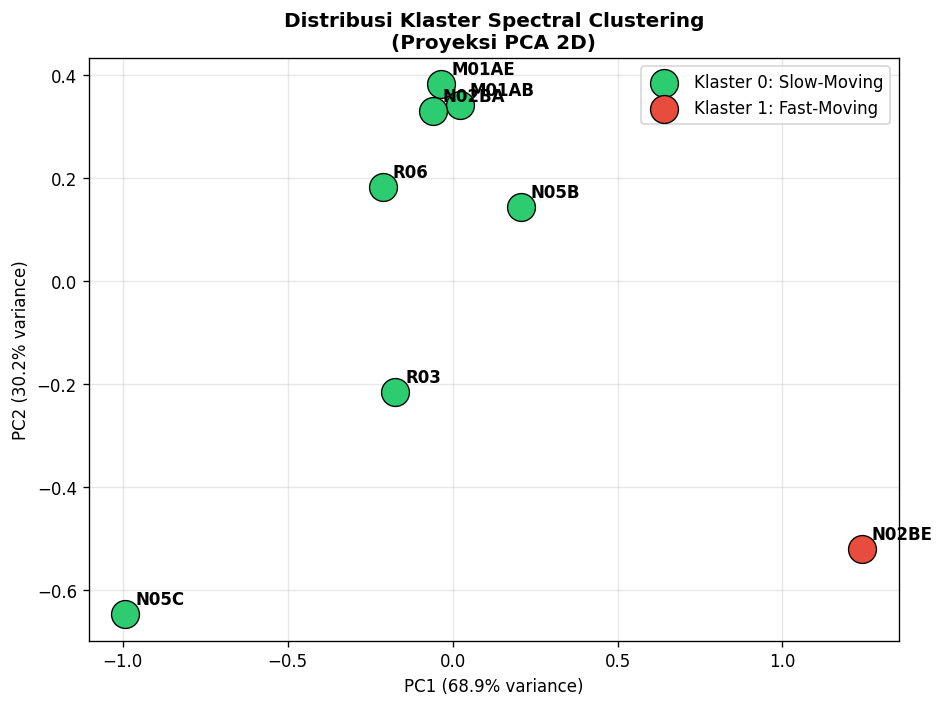

plot_scatter_klaster.png disimpan


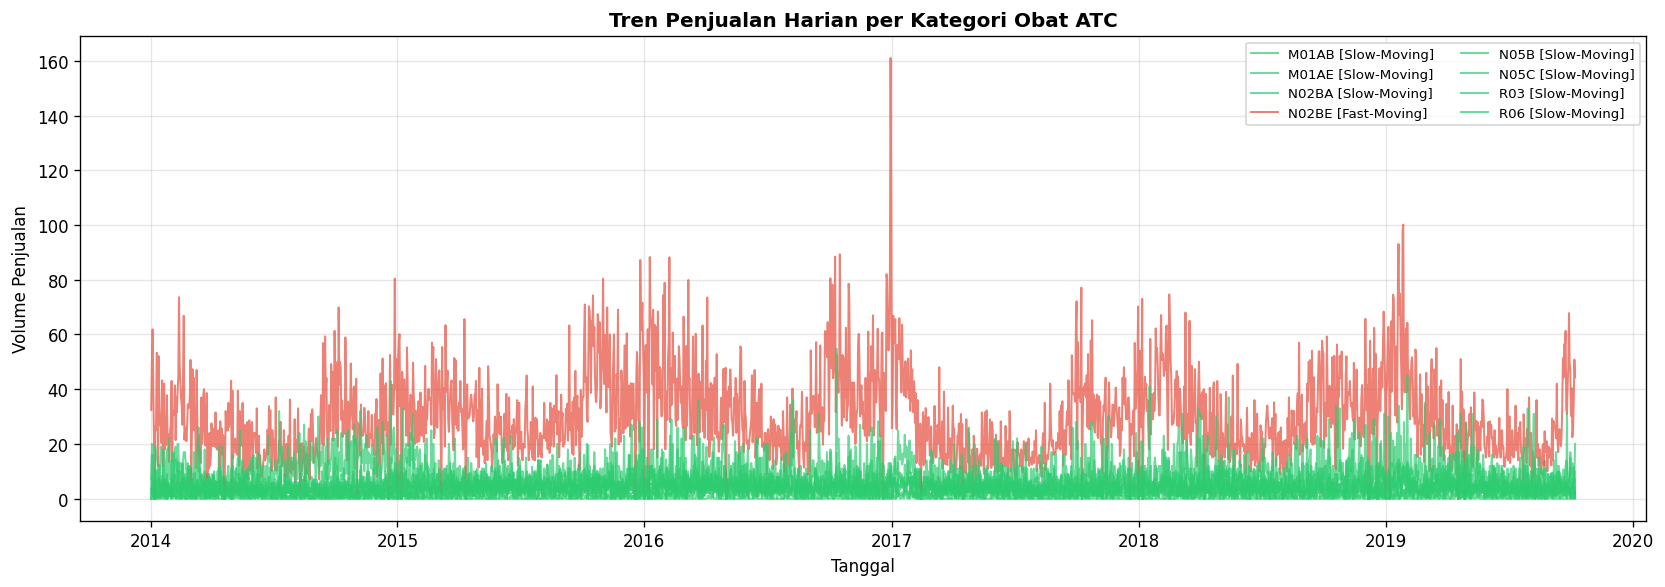

plot_tren_harian.png disimpan


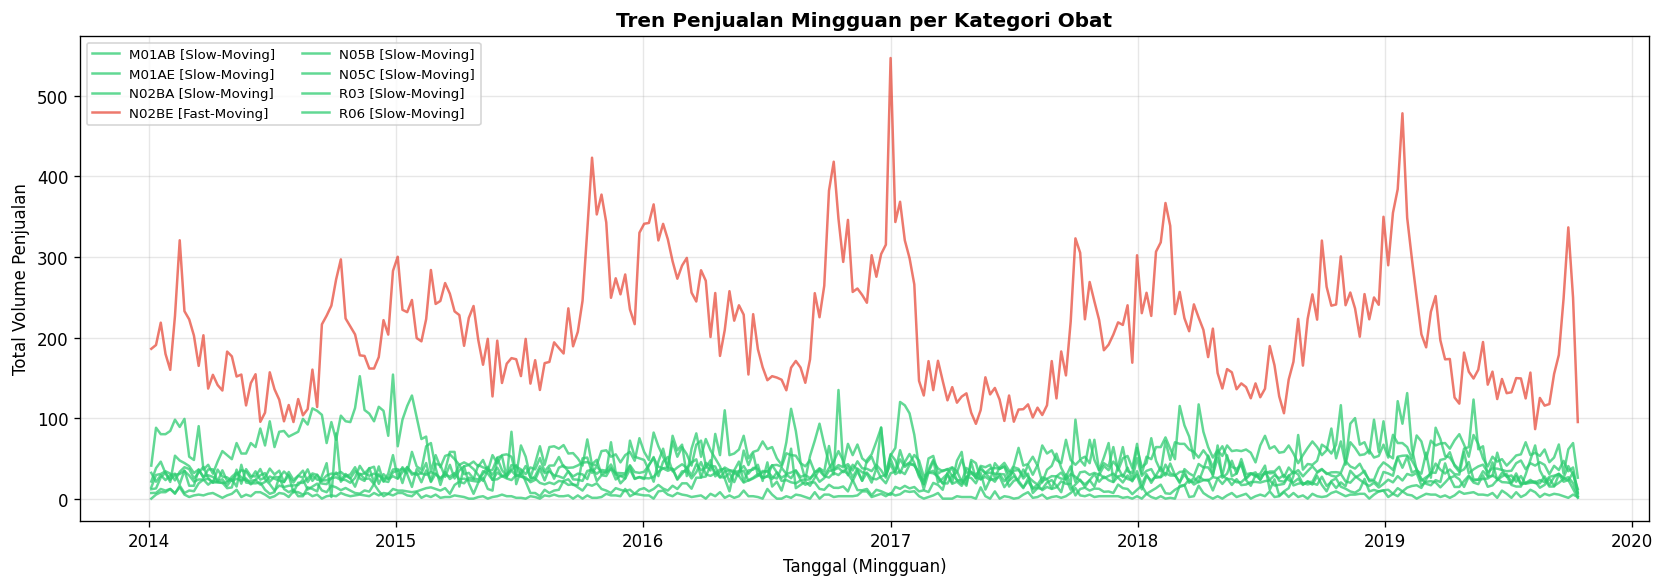

plot_tren_mingguan.png disimpan


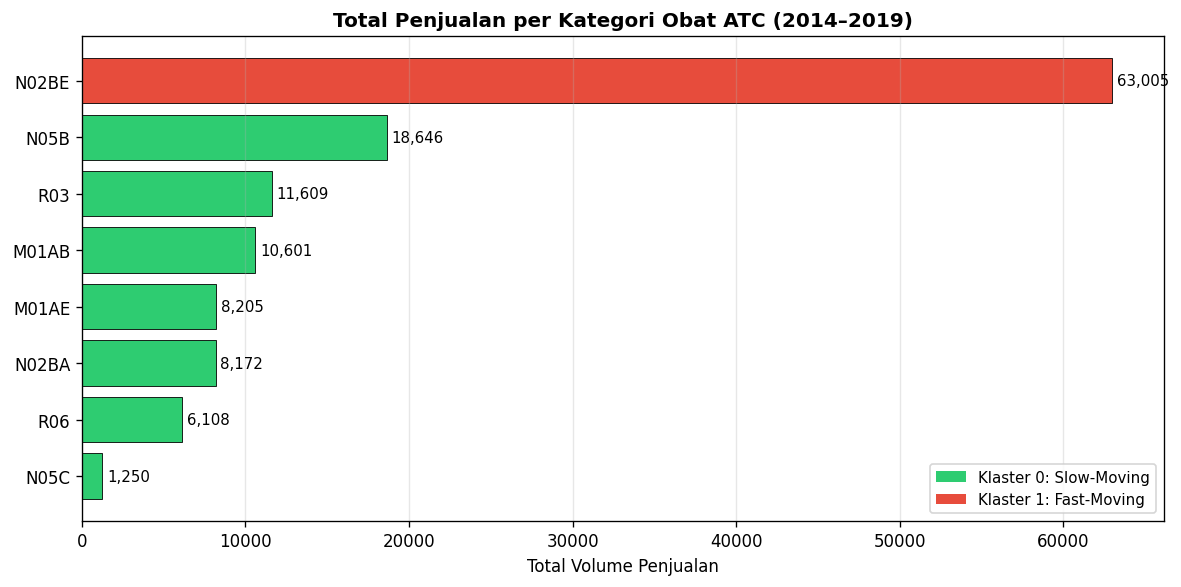

plot_total_penjualan.png disimpan


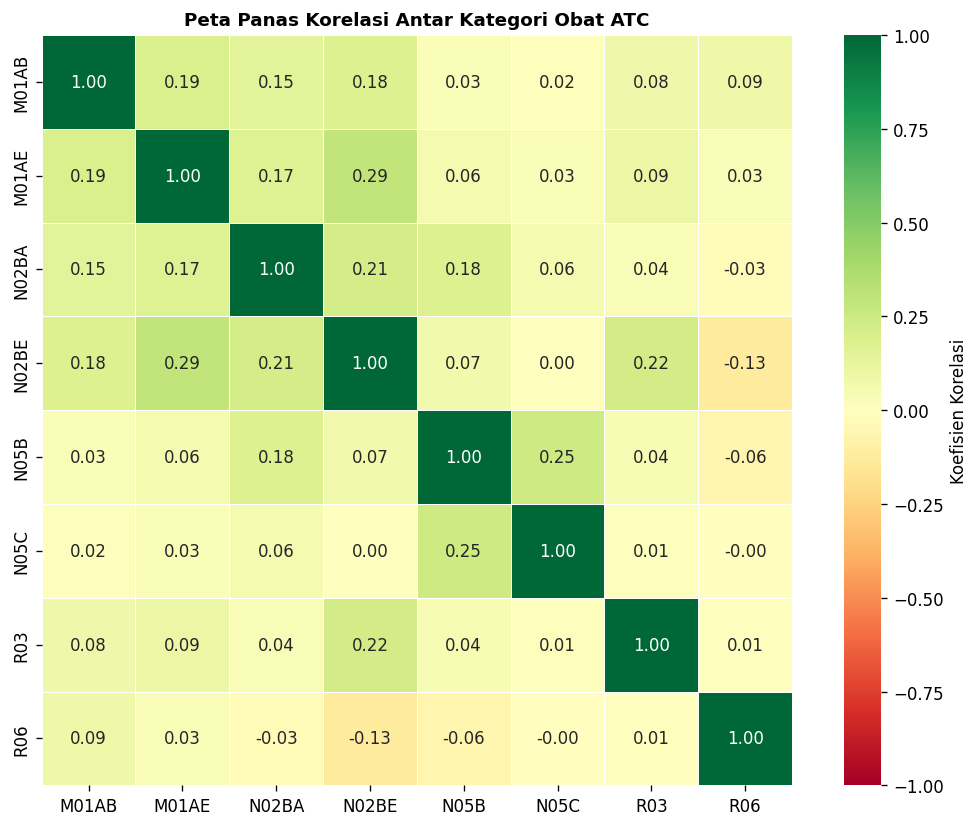

plot_heatmap_korelasi.png disimpan


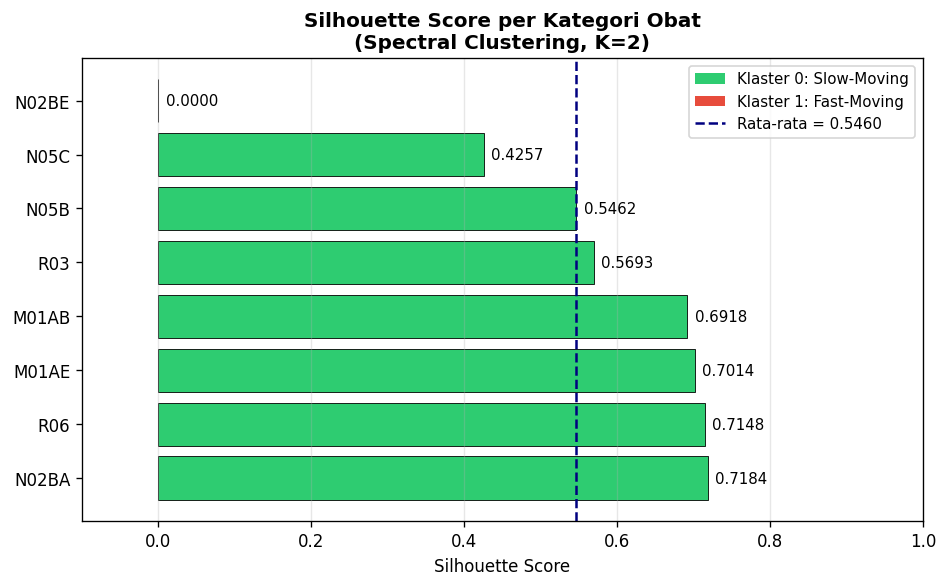

plot_silhouette_per_obat.png disimpan


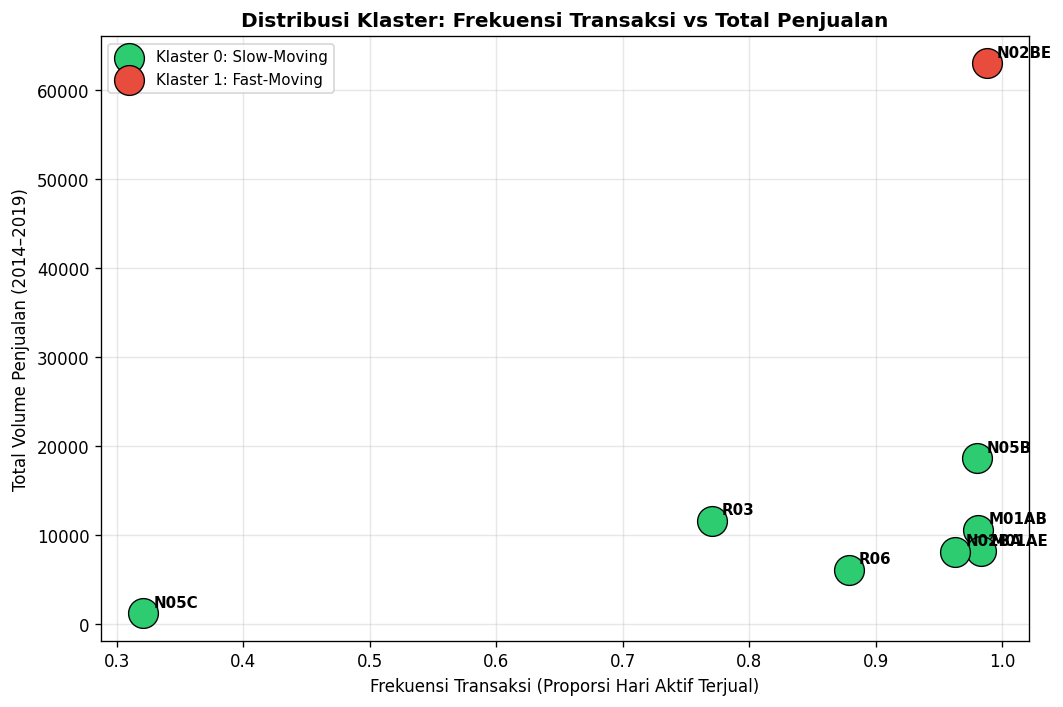

plot_scatter_frekuensi_volume.png disimpan

Semua visualisasi selesai. Lanjut ke Blok 11.


In [ ]:
#  BLOK 10 — OUTPUT: VISUALISASI HASIL


PALETTE = ["#2ECC71", "#E74C3C", "#3498DB", "#F39C12", "#9B59B6"]
cluster_colors = {k: PALETTE[i % len(PALETTE)]
                  for i, k in enumerate(sorted(df_features["Klaster_Spectral"].unique()))}

# ── PLOT A: Scatter PCA 2D — Spectral Clustering ─────────────────────
pca   = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

fig, ax = plt.subplots(figsize=(8, 6))
for k in sorted(df_features["Klaster_Spectral"].unique()):
    idx = np.where(labels_spectral == k)[0]
    lbl = label_lookup.get(df_features.iloc[idx[0]]["Kategori_ATC"], f"Klaster {k}")
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1],
               color=cluster_colors[k], s=280,
               label=f"Klaster {k}: {lbl}",
               edgecolors="black", lw=0.8, zorder=3)
    for i in idx:
        ax.annotate(ATC_COLS[i], xy=(X_pca[i, 0], X_pca[i, 1]),
                    xytext=(6, 6), textcoords="offset points",
                    fontsize=10, fontweight="bold")
ax.set_title("Distribusi Klaster Spectral Clustering\n(Proyeksi PCA 2D)",
             fontsize=12, fontweight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_scatter_klaster.png", bbox_inches="tight")
plt.show()
print("plot_scatter_klaster.png disimpan")

# ── PLOT B: Tren Penjualan Harian ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
for col in ATC_COLS:
    ax.plot(df["datum"], df[col],
            label=f"{col} [{label_lookup[col]}]",
            color=cluster_colors[klaster_lookup[col]],
            alpha=0.7, linewidth=1.2)
ax.set_title("Tren Penjualan Harian per Kategori Obat ATC",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Volume Penjualan")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_tren_harian.png", bbox_inches="tight")
plt.show()
print("plot_tren_harian.png disimpan")

# ── PLOT C: Tren Penjualan Mingguan ──────────────────────────────────
df_wk = df.set_index("datum")[ATC_COLS].resample("W").sum()
fig, ax = plt.subplots(figsize=(14, 5))
for col in ATC_COLS:
    ax.plot(df_wk.index, df_wk[col],
            label=f"{col} [{label_lookup[col]}]",
            color=cluster_colors[klaster_lookup[col]],
            alpha=0.75, linewidth=1.5)
ax.set_title("Tren Penjualan Mingguan per Kategori Obat",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Tanggal (Mingguan)")
ax.set_ylabel("Total Volume Penjualan")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_tren_mingguan.png", bbox_inches="tight")
plt.show()
print("plot_tren_mingguan.png disimpan")

# ── PLOT D: Bar Chart Total Penjualan ─────────────────────────────────
df_sorted  = df_features.sort_values("Total_Sales", ascending=True)
bar_colors = [cluster_colors[k] for k in df_sorted["Klaster_Spectral"]]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(df_sorted["Kategori_ATC"], df_sorted["Total_Sales"],
               color=bar_colors, edgecolor="black", linewidth=0.5)
for bar, val in zip(bars, df_sorted["Total_Sales"]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=9)
legend_el = [mpatches.Patch(facecolor=cluster_colors[k],
                             label=f"Klaster {k}: {label_map[k]}")
             for k in sorted(cluster_colors.keys())]
ax.legend(handles=legend_el, fontsize=9)
ax.set_title("Total Penjualan per Kategori Obat ATC (2014–2019)",
             fontweight="bold")
ax.set_xlabel("Total Volume Penjualan")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("plot_total_penjualan.png", bbox_inches="tight")
plt.show()
print("plot_total_penjualan.png disimpan")

# ── PLOT E: Heatmap Korelasi ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[ATC_COLS].corr(), annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-1, vmax=1, linewidths=0.5, square=True, ax=ax,
            cbar_kws={"label": "Koefisien Korelasi"})
ax.set_title("Peta Panas Korelasi Antar Kategori Obat ATC",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("plot_heatmap_korelasi.png", bbox_inches="tight")
plt.show()
print("plot_heatmap_korelasi.png disimpan")

# ── PLOT F: Silhouette Score per Kategori Obat ───────────────────────
df_sil_sorted = df_features.sort_values(
    ["Klaster_Spectral", "Silhouette_Score"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    df_sil_sorted["Kategori_ATC"],
    df_sil_sorted["Silhouette_Score"],
    color=[cluster_colors[k] for k in df_sil_sorted["Klaster_Spectral"]],
    edgecolor="black", linewidth=0.5
)
ax.axvline(sil_sc, color="navy", linestyle="--", linewidth=1.5,
           label=f"Rata-rata Silhouette = {sil_sc:.4f}")
for bar, val in zip(bars, df_sil_sorted["Silhouette_Score"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}", va="center", fontsize=9)
legend_el = [mpatches.Patch(facecolor=cluster_colors[k],
                             label=f"Klaster {k}: {label_map[k]}")
             for k in sorted(cluster_colors.keys())]
legend_el.append(plt.Line2D([0], [0], color="navy", linestyle="--",
                             label=f"Rata-rata = {sil_sc:.4f}"))
ax.legend(handles=legend_el, fontsize=9)
ax.set_title("Silhouette Score per Kategori Obat\n(Spectral Clustering, K=2)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Silhouette Score")
ax.set_xlim(-0.1, 1.0)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("plot_silhouette_per_obat.png", bbox_inches="tight")
plt.show()
print("plot_silhouette_per_obat.png disimpan")

# ── PLOT G: Frekuensi Transaksi vs Total Penjualan ───────────────────
fig, ax = plt.subplots(figsize=(9, 6))
for k in sorted(df_features["Klaster_Spectral"].unique()):
    idx = df_features["Klaster_Spectral"] == k
    lbl = df_features.loc[idx, "Label_Bisnis"].values[0]
    ax.scatter(df_features.loc[idx, "Freq_Transaksi"],
               df_features.loc[idx, "Total_Sales"],
               color=cluster_colors[k], s=320,
               label=f"Klaster {k}: {lbl}",
               edgecolors="black", lw=0.8, zorder=3)
    for i in df_features[idx].index:
        ax.annotate(df_features.loc[i, "Kategori_ATC"],
                    xy=(df_features.loc[i, "Freq_Transaksi"],
                        df_features.loc[i, "Total_Sales"]),
                    xytext=(6, 4), textcoords="offset points",
                    fontsize=9, fontweight="bold")
ax.set_title("Distribusi Klaster: Frekuensi Transaksi vs Total Penjualan",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Frekuensi Transaksi (Proporsi Hari Aktif Terjual)")
ax.set_ylabel("Total Volume Penjualan (2014–2019)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_scatter_frekuensi_volume.png", bbox_inches="tight")
plt.show()
print("plot_scatter_frekuensi_volume.png disimpan")

print("\nSemua visualisasi selesai. Lanjut ke Blok 11.")

In [ ]:
#   BLOK 11 — OUTPUT: EKSPOR DATA CSV
#   Integrasi BI — Google Looker Studio

#  Profil Klaster per Kategori Obat
df_profil = df_features[[
    "Kategori_ATC", "Total_Sales", "Mean_Daily", "Std_Daily",
    "Max_Daily", "Min_Daily", "Freq_Transaksi", "Coef_Variation",
    "Klaster_Spectral", "Label_Bisnis", "Indeks_Margin",
    "Rekomendasi", "Silhouette_Score"
]].copy()
df_profil.to_csv("output_profil_klaster.csv", index=False)
print("[1] output_profil_klaster.csv disimpan")
display(df_profil)

#  Data Harian + Label Klaster
df_daily = df[["datum", "Year", "Month", "Weekday Name"] + ATC_COLS].copy()
for col in ATC_COLS:
    df_daily[f"{col}_klaster"] = klaster_lookup[col]
    df_daily[f"{col}_label"]   = label_lookup[col]
df_daily.to_csv("output_data_harian_labeled.csv", index=False)
print(f"[2] output_data_harian_labeled.csv disimpan  ({df_daily.shape[0]:,} baris)")

#  Tren Mingguan per Klaster
df_wk2 = df.set_index("datum")[ATC_COLS].resample("W").sum().reset_index()
df_wk2.columns = ["Tanggal"] + ATC_COLS
for k in sorted(df_features["Klaster_Spectral"].unique()):
    obat_k = df_features[df_features["Klaster_Spectral"] == k]["Kategori_ATC"].tolist()
    lbl    = label_map[k].replace(" ", "_")
    df_wk2[f"Total_{lbl}"] = df_wk2[obat_k].sum(axis=1)
df_wk2.to_csv("output_tren_mingguan.csv", index=False)
print(f"[3] output_tren_mingguan.csv disimpan  ({df_wk2.shape[0]} minggu)")

#  Evaluasi (sudah disimpan di Blok 9)
print("[4] output_evaluasi.csv sudah disimpan di Blok 9")

#  Ringkasan Akhir
print("\n" + "=" * 62)
print("  RINGKASAN AKHIR PENELITIAN")
print("=" * 62)
print(f"\n  Dataset   : salesdaily.csv ({len(df):,} baris, 2014–2019)")
print(f"  Metode    : Spectral Clustering (Gaussian RBF, σ=1)")
print(f"  K Optimal : {best_k} klaster\n")

for k in sorted(label_map.keys()):
    obat = df_features[df_features["Klaster_Spectral"] == k]["Kategori_ATC"].tolist()
    lbl  = label_map[k]
    rek  = rek_map.get(lbl, "-")
    ts   = df_features[df_features["Klaster_Spectral"] == k]["Total_Sales"].sum()
    print(f"  Klaster {k} — {lbl}")
    print(f"  Anggota       : {obat}")
    print(f"  Total Sales   : {ts:,.2f} unit")
    print(f"  Rekomendasi   : {rek}\n")

print(f"  Silhouette Coefficient : {sil_sc:.4f}  ({interpretasi_sil(sil_sc)})")
print(f"  Davies-Bouldin Index   : {dbi_sc:.4f}  ({interpretasi_dbi(dbi_sc)})")
print(f"  Validasi K-Means       : {'Identik (robust)' if (df_features['Klaster_Spectral'].values == df_features['Klaster_KMeans'].values).all() else 'Berbeda'}")


print()
print(" SEMUA PROSES SELESAI.")

[1] output_profil_klaster.csv disimpan


,Kategori_ATC,Total_Sales,Mean_Daily,Std_Daily,Max_Daily,Min_Daily,Freq_Transaksi,Coef_Variation,Klaster_Spectral,Label_Bisnis,Indeks_Margin,Rekomendasi,Silhouette_Score
0,M01AB,10600.937083,5.033683,2.737579,17.340000,0.0,0.981007,0.543852,0,Slow-Moving,Sedang,Kurangi kuota pemesanan,0.691838
1,M01AE,8204.618646,3.895830,2.133337,14.463000,0.0,0.982906,0.547595,0,Slow-Moving,Sedang,Kurangi kuota pemesanan,0.701369
2,N02BA,8172.209000,3.880441,2.384010,16.000000,0.0,0.962963,0.614366,0,Slow-Moving,Rendah,Kurangi kuota pemesanan,0.718429
3,N02BE,63005.402708,29.917095,15.590966,161.000000,0.0,0.987654,0.521139,1,Fast-Moving,Tinggi,Prioritas restock utama,0.000000
4,N05B,18645.737500,8.853627,5.605605,54.833333,0.0,0.979582,0.633142,0,Slow-Moving,Tinggi,Kurangi kuota pemesanan,0.546228
5,N05C,1249.958333,0.593522,1.092988,9.000000,0.0,0.320988,1.841528,0,Slow-Moving,Tinggi,Kurangi kuota pemesanan,0.425704
6,R03,11608.822917,5.512262,6.428736,45.000000,0.0,0.770180,1.166261,0,Slow-Moving,Sedang,Kurangi kuota pemesanan,0.569326
7,R06,6107.817500,2.900198,2.415816,15.000000,0.0,0.878443,0.832983,0,Slow-Moving,Rendah,Kurangi kuota pemesanan,0.714779


[2] output_data_harian_labeled.csv disimpan  (2,106 baris)
[3] output_tren_mingguan.csv disimpan  (302 minggu)
[4] output_evaluasi.csv sudah disimpan di Blok 9

  RINGKASAN AKHIR PENELITIAN

  Dataset   : salesdaily.csv (2,106 baris, 2014–2019)
  Metode    : Spectral Clustering (Gaussian RBF, σ=1)
  K Optimal : 2 klaster

  Klaster 0 — Slow-Moving
  Anggota       : ['M01AB', 'M01AE', 'N02BA', 'N05B', 'N05C', 'R03', 'R06']
  Total Sales   : 64,590.10 unit
  Rekomendasi   : Kurangi kuota pemesanan

  Klaster 1 — Fast-Moving
  Anggota       : ['N02BE']
  Total Sales   : 63,005.40 unit
  Rekomendasi   : Prioritas restock utama

  Silhouette Coefficient : 0.5460  (Reasonable Structure  (Cukup Baik))
  Davies-Bouldin Index   : 0.2681  (Baik (separasi antar klaster cukup jelas))
  Validasi K-Means       : Identik (robust)

 SEMUA PROSES SELESAI.
